In [1]:
# Import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import nltk

nltk.download("punkt")
nltk.download("punkt_tab")

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\ASUS\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\ASUS\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [2]:

# Load Dataset
data = pd.read_csv('../review_gopay_newest_sort.csv')
print("Jumlah data:", len(data))

#Melihat Data Awal
# 10 data pertama
print(data.head(5))
# 10 data terakhir
print(data.tail(5))

# Informasi dataset
data.info()

#ukuran dataset
print("Ukuran dataset:", data.shape)

Jumlah data: 123253
          userName                                            content  score  \
0  Pengguna Google                                             Mantap      5   
1  Pengguna Google                          Bagus dan mudah digunakan      5   
2  Pengguna Google                                               Good      5   
3  Pengguna Google  Sangat membantu orang menengah mantap semoga s...      5   
4  Pengguna Google                                Ga ribet .. Sukaaaa      5   

   thumbsUpCount reviewCreatedVersion                   at  
0              0               1.24.1  2024-07-07 16:58:06  
1              0               1.24.1  2024-07-07 16:57:08  
2              0               1.24.1  2024-07-07 16:52:38  
3              0               1.24.1  2024-07-07 16:52:36  
4              0               1.24.1  2024-07-07 16:52:09  
                         userName  \
123248  MUHAMAD IRFA RAMDAN RIFAI   
123249                 Xjaga Cell   
123250              Er

In [3]:
#melihat nama kolom
print("Nama kolom:", data.columns)

#melihat jumlah dokumen dalam dataset
jumlah_dokumen = len(data)
print("Jumlah dokumen:", jumlah_dokumen)

#  Memilih Kolom Teks
text_column = "content"       # ganti nama kolom teks yg sesuai dengan dataset 
texts = data[text_column]
print("kolom content:", texts.head(9))

#melihat contoh teks ulasan
for text in texts.head(10):
    print(text)
    print("-" * 80)

Nama kolom: Index(['userName', 'content', 'score', 'thumbsUpCount', 'reviewCreatedVersion',
       'at'],
      dtype='str')
Jumlah dokumen: 123253
kolom content: 0                                               Mantap
1                            Bagus dan mudah digunakan
2                                                 Good
3    Sangat membantu orang menengah mantap semoga s...
4                                  Ga ribet .. Sukaaaa
5                                      Sangat membantu
6                                   Mantap pakay gopay
7                                 mantap mantap mantap
8              Layanan sang Mudah Dan Sangat Memuaskan
Name: content, dtype: str
Mantap
--------------------------------------------------------------------------------
Bagus dan mudah digunakan
--------------------------------------------------------------------------------
Good
--------------------------------------------------------------------------------
Sangat membantu orang menengah mant

In [4]:
# Memeriksa missing value
print("Jumlah missing value setiap kolom:")
print(data.isnull().sum())

# Menghapus data kosong pada kolom teks
print("Dokumen sebelum menghapus data kosong:", len(data))

data = data.dropna(subset=[text_column]).copy()

print("Dokumen setelah menghapus data kosong:", len(data))

Jumlah missing value setiap kolom:
userName                    0
content                     0
score                       0
thumbsUpCount               0
reviewCreatedVersion    15928
at                          0
dtype: int64
Dokumen sebelum menghapus data kosong: 123253
Dokumen setelah menghapus data kosong: 123253


In [5]:
# Memeriksa duplikasi
data.duplicated().sum()
print("Jumlah dokumen duplikat:", data.duplicated().sum())

# Memeriksa duplikasi pada kolom teks
data[text_column].duplicated().sum()
print("Jumlah teks duplikat:",data[text_column].duplicated().sum())

# Menghapus teks duplikat
data = data.drop_duplicates(subset=[text_column])
print("Jumlah dokumen setelah menghapus duplikat:", len(data))

# Menghitung jumlah karakter
data["jumlah_karakter"] = data[text_column].astype(str).apply(len)
print(data["jumlah_karakter"].head(10))

# Menghitung jumlah kata
data["jumlah_kata"] = data[text_column].astype(str).apply(
    lambda x: len(x.split())
)
print(data[[text_column, "jumlah_kata"]].head(10))


Jumlah dokumen duplikat: 2
Jumlah teks duplikat: 44822
Jumlah dokumen setelah menghapus duplikat: 78431
0     6
1    25
2     4
3    63
4    19
5    15
6    18
7    20
8    39
9     9
Name: jumlah_karakter, dtype: int64
                                             content  jumlah_kata
0                                             Mantap            1
1                          Bagus dan mudah digunakan            4
2                                               Good            1
3  Sangat membantu orang menengah mantap semoga s...            9
4                                Ga ribet .. Sukaaaa            4
5                                    Sangat membantu            2
6                                 Mantap pakay gopay            3
7                               mantap mantap mantap            3
8            Layanan sang Mudah Dan Sangat Memuaskan            6
9                                          Berbisnis            1


In [6]:
# Statistik jumlah kata
print("Statistik Jumlah Kata")
print(data["jumlah_kata"].describe())

print("Rata-rata kata per dokumen:", data["jumlah_kata"].mean())
print("Jumlah kata minimum:", data["jumlah_kata"].min())
print("Jumlah kata maksimum:", data["jumlah_kata"].max())


Statistik Jumlah Kata
count    78431.000000
mean         9.577233
std         10.477020
min          1.000000
25%          3.000000
50%          6.000000
75%         12.000000
max        105.000000
Name: jumlah_kata, dtype: float64
Rata-rata kata per dokumen: 9.577233491859086
Jumlah kata minimum: 1
Jumlah kata maksimum: 105


In [7]:
# Menghitung jumlah kalimat
from nltk.tokenize import sent_tokenize
data["jumlah_kalimat"] = data[text_column].fillna("").astype(str).apply(
    lambda x: len(sent_tokenize(x))
)

# Contoh tokenisasi kalimat
text = "Saya belajar NLP. NLP sangat menarik."
sentences = sent_tokenize(text)
print(sentences)

print("Jumlah kalimat setiap dokumen:")
print(data["jumlah_kalimat"].head(10))

# Statistik corpus
print("Jumlah dokumen :", len(data))
print("Jumlah kata    :", data["jumlah_kata"].sum())
print("Jumlah kalimat :", data["jumlah_kalimat"].sum())
print("Jumlah karakter:", data["jumlah_karakter"].sum())

# Menampilkan dokumen terpendek dan terpanjang
print("\nDokumen terpendek:")
idx_min = data["jumlah_kata"].idxmin()
print("Teks:", data.loc[idx_min, text_column])
print("Jumlah kata:", data.loc[idx_min, "jumlah_kata"])

print("\nDokumen terpanjang:")
idx_max = data["jumlah_kata"].idxmax()
print("Teks:", data.loc[idx_max, text_column])
print("Jumlah kata:", data.loc[idx_max, "jumlah_kata"])

['Saya belajar NLP.', 'NLP sangat menarik.']
Jumlah kalimat setiap dokumen:
0    1
1    1
2    1
3    1
4    1
5    1
6    1
7    1
8    1
9    1
Name: jumlah_kalimat, dtype: int64
Jumlah dokumen : 78431
Jumlah kata    : 751152
Jumlah kalimat : 92810
Jumlah karakter: 4721464

Dokumen terpendek:
Teks: Mantap
Jumlah kata: 1

Dokumen terpanjang:
Teks: Stock Cheek Pad Dll Eps Sid Bluetooth: 1000 Eps Sid Bluetooth Besar: 0 Eps Chin TTC: 900 Eps Chin Enduro: 0 Eps Chin Striker: 0 Cheek Pad RC 10: 0 Cheek Pad Vendetta: 100 Cheek Pad Venom RF 2: 1400 Cheek Pad Centro R: 600 Cheek Pad Dj Vega: 400 Cheek Pad K2 Rider: 656 Cheek Pad Cross H: 0 Cheek Pad CL 28: 0 Cheek Pad Pro Rider: 600 Cheek Pad Rumble L: 300 Cheek Pad Enduro: 0 Cheek Pad Zarra: 960 Cheek Pad TFF M: 100 Cheek Pad Dynamic L: 1500 Cheek Pad Dynamic M: 250 Cheek Pad NFJ L: 540 Cheek P
Jumlah kata: 105


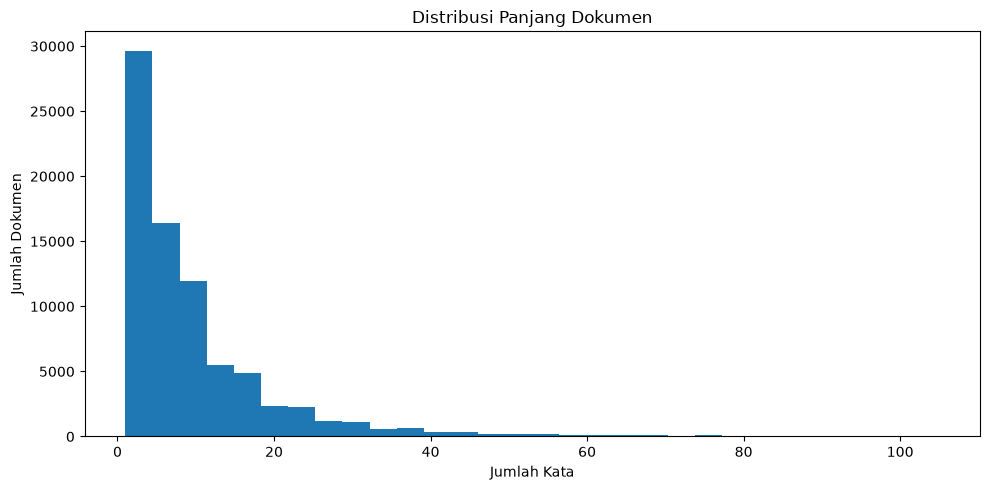

In [8]:
# Visualisasi Distribusi Panjang Dokumen
import pandas as pd
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.hist(data["jumlah_kata"], bins=30)
plt.xlabel("Jumlah Kata")
plt.ylabel("Jumlah Dokumen")
plt.title("Distribusi Panjang Dokumen")
plt.tight_layout()
plt.show()
